In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, classification_report,
                             ConfusionMatrixDisplay)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold,
                                     cross_val_score, train_test_split)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
pd.set_option("display.max_columns", 20)
plt.rcParams["figure.figsize"] = (10, 5)
print("Библиотеки загружены.")

Библиотеки загружены.


In [2]:
wine = load_wine()
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = pd.Series(wine.target, name="class")

print(f"Количество объектов: {X.shape[0]}")
print(f"Количество признаков: {X.shape[1]}")
print(f"Классов: {y.nunique()}")
print("Названия классов:", ", ".join(wine.target_names))
print("Пропущенные значения:", int(X.isna().sum().sum()))

display(X.head())
display(pd.DataFrame({"Класс": y.value_counts().sort_index().index,
                      "Количество объектов": y.value_counts().sort_index().values}))

Количество объектов: 178
Количество признаков: 13
Классов: 3
Названия классов: class_0, class_1, class_2
Пропущенные значения: 0


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


,Класс,Количество объектов
0,0,59
1,1,71
2,2,48


Признаки с самым большим и маленьким стандартным отклонением:


,min,max,std
proline,278.00,1680.00,314.907474
magnesium,70.00,162.00,14.282484
alcalinity_of_ash,10.60,30.00,3.339564
color_intensity,1.28,13.00,2.318286
proanthocyanins,0.41,3.58,0.572359
ash,1.36,3.23,0.274344
hue,0.48,1.71,0.228572
nonflavanoid_phenols,0.13,0.66,0.124453


Отношение максимального std к минимальному: 2530.3


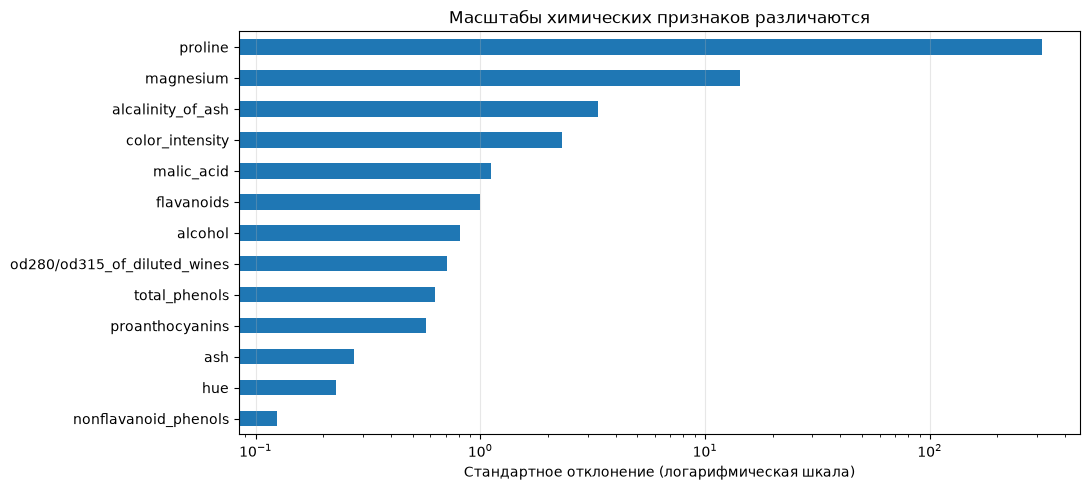

In [3]:
feature_stats = pd.DataFrame({
    "min": X.min(),
    "max": X.max(),
    "std": X.std(),
}).sort_values("std", ascending=False)

print("Признаки с самым большим и маленьким стандартным отклонением:")
display(pd.concat([feature_stats.head(4), feature_stats.tail(4)]))
print(f"Отношение максимального std к минимальному: "
      f"{feature_stats['std'].max() / feature_stats['std'].min():.1f}")

fig, ax = plt.subplots(figsize=(11, 5))
feature_stats["std"].sort_values().plot.barh(ax=ax)
ax.set_xscale("log")
ax.set_xlabel("Стандартное отклонение (логарифмическая шкала)")
ax.set_title("Масштабы химических признаков различаются")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Разделение на обучение и тест

Используем 75% наблюдений для обучения и 25% для финальной проверки. `stratify=y` сохраняет близкие пропорции классов в обеих частях.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print(f"Обучающая выборка: {X_train.shape[0]} объектов")
print(f"Тестовая выборка: {X_test.shape[0]} объектов")
print("Классы в обучении:", y_train.value_counts().sort_index().to_dict())
print("Классы в тесте:", y_test.value_counts().sort_index().to_dict())

Обучающая выборка: 133 объектов
Тестовая выборка: 45 объектов
Классы в обучении: {0: 44, 1: 53, 2: 36}
Классы в тесте: {0: 15, 1: 18, 2: 12}


,Метрика,Стандартизация,CV accuracy (средняя),CV std
0,euclidean,Нет,0.662,0.064
1,euclidean,Да,0.955,0.043
2,manhattan,Нет,0.707,0.063
3,manhattan,Да,0.985,0.018


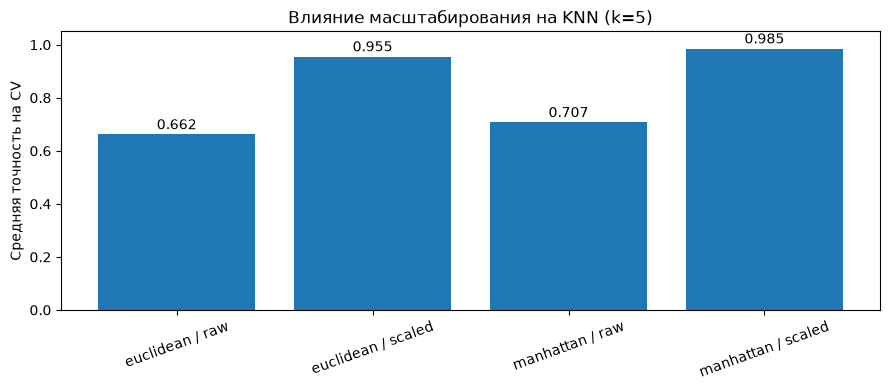

In [5]:
scaling_rows = []
for metric in ("euclidean", "manhattan"):
    for scaled in (False, True):
        steps = []
        if scaled:
            steps.append(("scaler", StandardScaler()))
        steps.append(("knn", KNeighborsClassifier(n_neighbors=5, metric=metric)))
        model = Pipeline(steps)
        scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy")
        scaling_rows.append({
            "Метрика": metric,
            "Стандартизация": "Да" if scaled else "Нет",
            "CV accuracy (средняя)": scores.mean(),
            "CV std": scores.std(),
        })
scaling_table = pd.DataFrame(scaling_rows)
display(scaling_table.style.format({"CV accuracy (средняя)": "{:.3f}", "CV std": "{:.3f}"}))

fig, ax = plt.subplots(figsize=(9, 4))
labels = [f"{r['Метрика']} / {'scaled' if r['Стандартизация']=='Да' else 'raw'}"
          for _, r in scaling_table.iterrows()]
ax.bar(labels, scaling_table["CV accuracy (средняя)"])
ax.set_ylim(0, 1.05)
ax.set_ylabel("Средняя точность на CV")
ax.set_title("Влияние масштабирования на KNN (k=5)")
ax.tick_params(axis="x", rotation=20)
for i, score in enumerate(scaling_table["CV accuracy (средняя)"]):
    ax.text(i, min(float(score) + 0.02, 1.01), f"{score:.3f}", ha="center")
plt.tight_layout()
plt.show()

In [6]:
param_grid = {
    "knn__n_neighbors": list(range(1, 26)),
    "knn__metric": ["euclidean", "manhattan"],
}

knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier()),
])
search_13 = GridSearchCV(
    knn_pipeline, param_grid, cv=cv, scoring="accuracy", n_jobs=1, refit=True
)
search_13.fit(X_train, y_train)

print("Оптимальные параметры (13 признаков):", search_13.best_params_)
print(f"Лучшая средняя CV accuracy: {search_13.best_score_:.4f}")

cv_results_13 = pd.DataFrame(search_13.cv_results_)
summary_13 = (
    cv_results_13.sort_values("mean_test_score", ascending=False)
    .groupby("param_knn__metric", as_index=False)
    .first()[["param_knn__metric", "param_knn__n_neighbors", "mean_test_score", "std_test_score"]]
)
summary_13.columns = ["Метрика", "Лучшее k", "CV accuracy", "CV std"]
display(summary_13.style.format({"CV accuracy": "{:.4f}", "CV std": "{:.4f}"}))

Оптимальные параметры (13 признаков): {'knn__metric': 'manhattan', 'knn__n_neighbors': 7}
Лучшая средняя CV accuracy: 0.9926


,Метрика,Лучшее k,CV accuracy,CV std
0,euclidean,23,0.9778,0.0296
1,manhattan,7,0.9926,0.0148


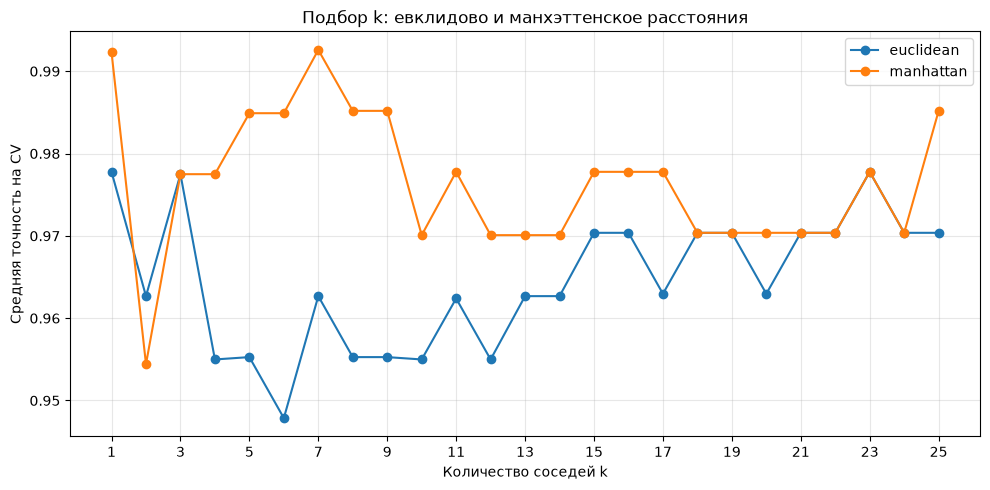

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
for metric in ("euclidean", "manhattan"):
    sub = cv_results_13[cv_results_13["param_knn__metric"] == metric].sort_values(
        "param_knn__n_neighbors"
    )
    ax.plot(sub["param_knn__n_neighbors"].astype(int),
            sub["mean_test_score"], marker="o", label=metric)
ax.set_xlabel("Количество соседей k")
ax.set_ylabel("Средняя точность на CV")
ax.set_title("Подбор k: евклидово и манхэттенское расстояния")
ax.set_xticks(range(1, 26, 2))
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

,Признаков,Метрика,k,Test accuracy
0,13 (исходные),euclidean,23,1.0000
1,13 (исходные),manhattan,7,0.9778


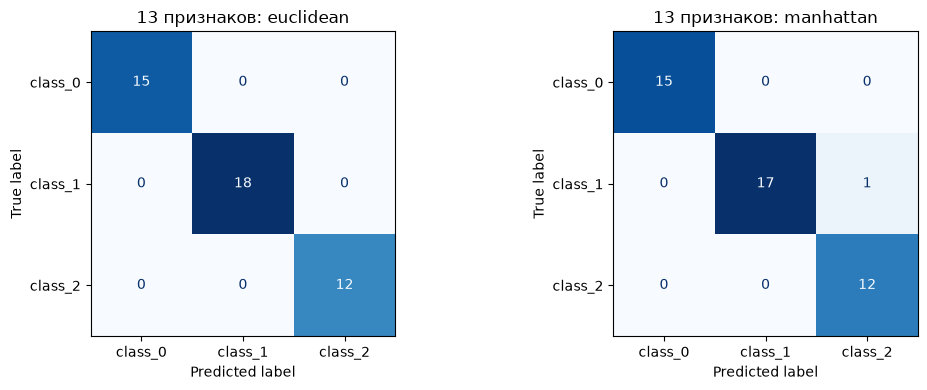

Отчёт по лучшей модели среди 13-мерных (выбрана по CV):
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        15
     class_1       1.00      0.94      0.97        18
     class_2       0.92      1.00      0.96        12

    accuracy                           0.98        45
   macro avg       0.97      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45



In [8]:
models_13 = {}
rows_13 = []
for metric in ("euclidean", "manhattan"):
    best_row = summary_13.loc[summary_13["Метрика"] == metric].iloc[0]
    k = int(best_row["Лучшее k"])
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=k, metric=metric)),
    ])
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    models_13[metric] = model
    rows_13.append({"Признаков": "13 (исходные)", "Метрика": metric,
                    "k": k, "Test accuracy": accuracy_score(y_test, pred)})

results_13 = pd.DataFrame(rows_13)
display(results_13.style.format({"Test accuracy": "{:.4f}"}))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axes, ("euclidean", "manhattan")):
    ConfusionMatrixDisplay.from_predictions(
        y_test, models_13[metric].predict(X_test),
        display_labels=wine.target_names, ax=ax, colorbar=False, cmap="Blues"
    )
    ax.set_title(f"13 признаков: {metric}")
plt.tight_layout()
plt.show()

print("Отчёт по лучшей модели среди 13-мерных (выбрана по CV):")
print(classification_report(
    y_test, search_13.best_estimator_.predict(X_test),
    target_names=wine.target_names, zero_division=0
))

Доля объяснённой дисперсии PC1 и PC2: [0.3575 0.1921]
Суммарно сохранено: 54.96% дисперсии


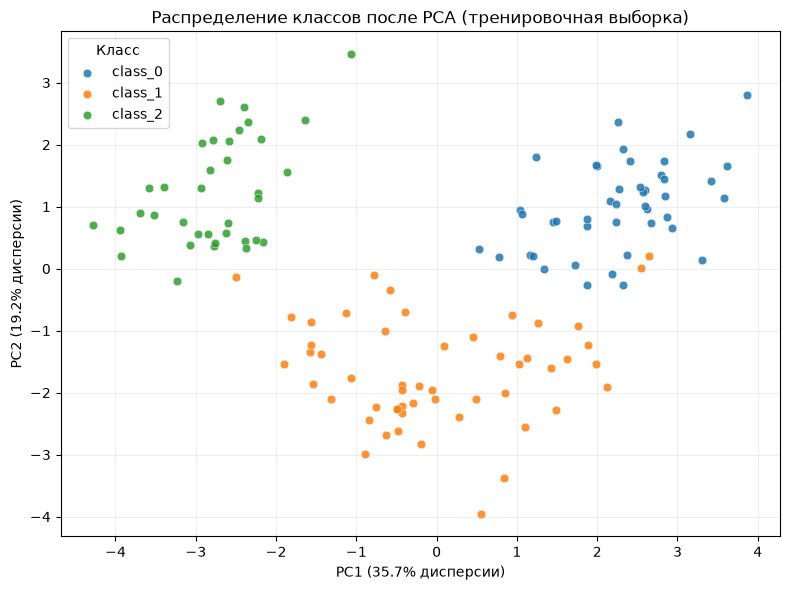

In [9]:
scaler_vis = StandardScaler().fit(X_train)
X_train_scaled = scaler_vis.transform(X_train)
X_test_scaled = scaler_vis.transform(X_test)
pca_vis = PCA(n_components=2, random_state=RANDOM_STATE).fit(X_train_scaled)
X_train_2d = pca_vis.transform(X_train_scaled)
X_test_2d = pca_vis.transform(X_test_scaled)

print("Доля объяснённой дисперсии PC1 и PC2:",
      np.round(pca_vis.explained_variance_ratio_, 4))
print(f"Суммарно сохранено: {sum(pca_vis.explained_variance_ratio_):.2%} дисперсии")

fig, ax = plt.subplots(figsize=(8, 6))
for target_id, name in enumerate(wine.target_names):
    mask = y_train.to_numpy() == target_id
    ax.scatter(X_train_2d[mask, 0], X_train_2d[mask, 1],
               label=name, s=38, alpha=0.85, edgecolors="white", linewidths=0.35)
ax.set_xlabel(f"PC1 ({pca_vis.explained_variance_ratio_[0]:.1%} дисперсии)")
ax.set_ylabel(f"PC2 ({pca_vis.explained_variance_ratio_[1]:.1%} дисперсии)")
ax.set_title("Распределение классов после PCA (тренировочная выборка)")
ax.legend(title="Класс")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [10]:
pca_knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=2, random_state=RANDOM_STATE)),
    ("knn", KNeighborsClassifier()),
])
search_2d = GridSearchCV(
    pca_knn_pipeline, param_grid, cv=cv, scoring="accuracy", n_jobs=1, refit=True
)
search_2d.fit(X_train, y_train)

cv_results_2d = pd.DataFrame(search_2d.cv_results_)
summary_2d = (
    cv_results_2d.sort_values("mean_test_score", ascending=False)
    .groupby("param_knn__metric", as_index=False)
    .first()[["param_knn__metric", "param_knn__n_neighbors", "mean_test_score", "std_test_score"]]
)
summary_2d.columns = ["Метрика", "Лучшее k", "CV accuracy", "CV std"]
print("Лучшие параметры для PCA (2D):", search_2d.best_params_)
display(summary_2d.style.format({"CV accuracy": "{:.4f}", "CV std": "{:.4f}"}))

models_2d = {}
rows_2d = []
for metric in ("euclidean", "manhattan"):
    best_row = summary_2d.loc[summary_2d["Метрика"] == metric].iloc[0]
    k = int(best_row["Лучшее k"])
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=2, random_state=RANDOM_STATE)),
        ("knn", KNeighborsClassifier(n_neighbors=k, metric=metric)),
    ])
    model.fit(X_train, y_train)
    models_2d[metric] = model
    rows_2d.append({"Признаков": "2 (PCA)", "Метрика": metric, "k": k,
                    "Test accuracy": accuracy_score(y_test, model.predict(X_test))})

results_2d = pd.DataFrame(rows_2d)
display(results_2d.style.format({"Test accuracy": "{:.4f}"}))

Лучшие параметры для PCA (2D): {'knn__metric': 'euclidean', 'knn__n_neighbors': 1}


,Метрика,Лучшее k,CV accuracy,CV std
0,euclidean,1,0.9852,0.0296
1,manhattan,18,0.9778,0.0296


,Признаков,Метрика,k,Test accuracy
0,2 (PCA),euclidean,1,0.8889
1,2 (PCA),manhattan,18,0.9556


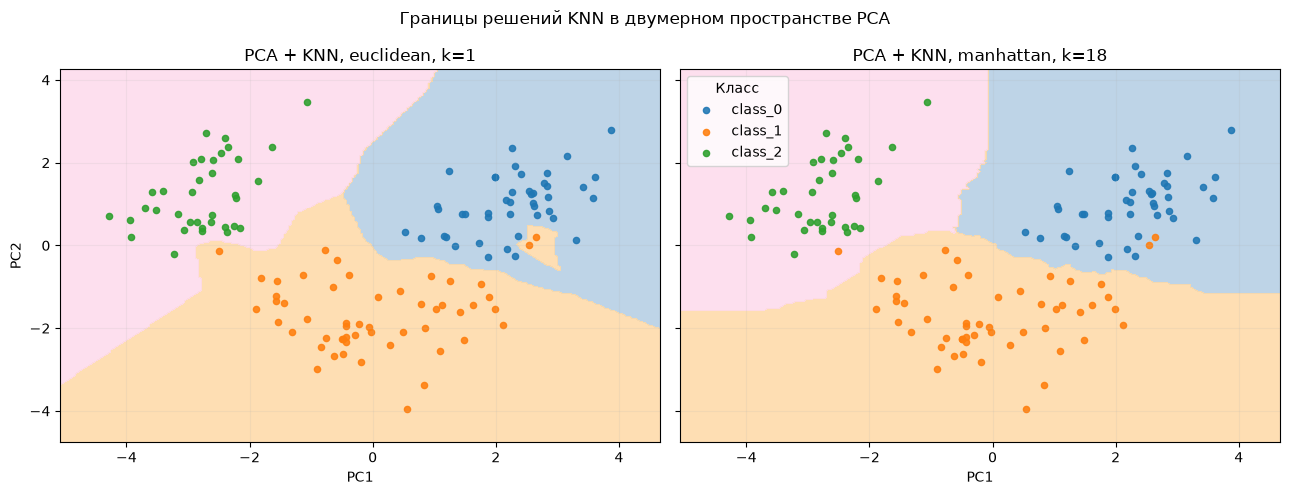

In [11]:
# Используем PCA-координаты, построенные по тренировочной выборке, для показа границ.
# Каждый двумерный KNN обучается только на преобразованном X_train.
x_min, x_max = X_train_2d[:, 0].min() - 0.8, X_train_2d[:, 0].max() + 0.8
y_min, y_max = X_train_2d[:, 1].min() - 0.8, X_train_2d[:, 1].max() + 0.8
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 220),
                     np.linspace(y_min, y_max, 220))
grid = np.column_stack((xx.ravel(), yy.ravel()))

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
for ax, metric in zip(axes, ("euclidean", "manhattan")):
    k = int(summary_2d.loc[summary_2d["Метрика"] == metric, "Лучшее k"].iloc[0])
    knn_on_components = KNeighborsClassifier(n_neighbors=k, metric=metric)
    knn_on_components.fit(X_train_2d, y_train)
    predictions_grid = knn_on_components.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, predictions_grid, levels=[-0.5, 0.5, 1.5, 2.5],
                cmap="Pastel1", alpha=0.85)
    for target_id, name in enumerate(wine.target_names):
        mask = y_train.to_numpy() == target_id
        ax.scatter(X_train_2d[mask, 0], X_train_2d[mask, 1],
                   label=name, s=20, alpha=0.88)
    ax.set_title(f"PCA + KNN, {metric}, k={k}")
    ax.set_xlabel("PC1")
    ax.grid(alpha=0.15)
axes[0].set_ylabel("PC2")
axes[1].legend(title="Класс", loc="best")
plt.suptitle("Границы решений KNN в двумерном пространстве PCA")
plt.tight_layout()
plt.show()

In [13]:
final_results = pd.concat([results_13, results_2d], ignore_index=True)
display(final_results.sort_values("Test accuracy", ascending=False).style.format({
    "Test accuracy": "{:.4f}"}))

best = final_results.sort_values("Test accuracy", ascending=False).iloc[0]


,Признаков,Метрика,k,Test accuracy
0,13 (исходные),euclidean,23,1.0000
1,13 (исходные),manhattan,7,0.9778
3,2 (PCA),manhattan,18,0.9556
2,2 (PCA),euclidean,1,0.8889


## Контрольные вопросы

1. **Почему без `StandardScaler` KNN может работать хуже?** Признаки с большими численными диапазонами непропорционально влияют на расстояния.
2. **Чем отличаются `euclidean` и `manhattan`?** Первая метрика вычисляет длину прямого отрезка, вторая — сумму модулей покоординатных разностей.
3. **Что делает параметр `n_neighbors`?** Задаёт количество ближайших объектов, участвующих в голосовании по классу.
4. **Зачем PCA?** Уменьшает число признаков и позволяет визуализировать многомерные наблюдения на плоскости, хотя часть информации может теряться.
5. **Почему `StandardScaler` и PCA включены в `Pipeline`?** Чтобы параметры преобразований вычислялись без использования данных проверочных фолдов или теста.

**Работа завершена.** Экспериментируйте с диапазоном `k` и `n_components` (2, 3, 5), чтобы увидеть влияние размерности на точность.